In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from google.colab import files
uploaded = files.upload()

df = pd.read_csv("lung_cancer.csv")
df.head(10)

Saving lung_cancer.csv to lung_cancer.csv


,SMOKING,YELLOW_FINGERS,ANXIETY,PEER_PRESSURE,CHRONIC DISEASE,FATIGUE,ALLERGY,WHEEZING,ALCOHOL CONSUMING,COUGHING,SHORTNESS OF BREATH,CHEST PAIN,LUNG_CANCER
0,1,2,2,1,1,NaN,NaN,2,2,2,2,2,YES
1,2,1,1,1,2,NaN,NaN,1,1,1,2,2,YES
2,1,1,1,2,1,NaN,NaN,2,1,2,2,2,NO
3,2,2,2,1,1,NaN,NaN,1,2,1,1,2,NO
4,1,2,1,1,1,NaN,NaN,2,1,2,2,1,NO
5,1,2,1,1,2,NaN,NaN,2,1,2,2,1,YES
6,2,1,1,1,1,NaN,NaN,2,2,2,2,2,YES
7,2,2,2,2,1,NaN,NaN,1,1,1,2,1,YES
8,2,1,2,1,1,NaN,NaN,1,1,1,1,1,NO
9,2,2,2,2,2,NaN,NaN,1,2,1,1,2,YES


In [ ]:


# Now, split features and target
X = df.drop('LUNG_CANCER', axis=1)
y = df['LUNG_CANCER']

print("Shape of X:",X.shape)
print("Shape of y:",y.shape)
print("Classes:",np.unique(y))
print("Missing values in final X:", X.isnull().sum().sum())

Shape of X: (309, 10)
Shape of y: (309,)
Classes: ['NO' 'YES']
Missing values in final X: 0


In [ ]:
#data exploration

print("first 5 rows of X:")
print(X.head())

print("first 5 target values:")
print(y[:5])

first 5 rows of X:
   SMOKING  YELLOW_FINGERS  ANXIETY  PEER_PRESSURE  CHRONIC DISEASE  WHEEZING  \
0        1               2        2              1                1         2   
1        2               1        1              1                2         1   
2        1               1        1              2                1         2   
3        2               2        2              1                1         1   
4        1               2        1              1                1         2   

   ALCOHOL CONSUMING  COUGHING  SHORTNESS OF BREATH  CHEST PAIN  
0                  2         2                    2           2  
1                  1         1                    2           2  
2                  1         2                    2           2  
3                  2         1                    1           2  
4                  1         2                    2           1  
first 5 target values:
0    YES
1    YES
2     NO
3     NO
4     NO
Name: LUNG_CANCER, dtype: obje

In [ ]:
#missing values

print("Missing values:", np.isnan(X).sum())




Missing values: SMOKING                  0
YELLOW_FINGERS           0
ANXIETY                  0
PEER_PRESSURE            0
CHRONIC DISEASE          0
FATIGUE                309
ALLERGY                309
WHEEZING                 0
ALCOHOL CONSUMING        0
COUGHING                 0
SHORTNESS OF BREATH      0
CHEST PAIN               0
dtype: int64


In [ ]:
#split dataset

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (247, 12)
Testing data: (62, 12)


In [ ]:
#feature scaling

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Scaling completed.")
#scaler.fit_transform(X_train)
#scaler.transform(X_test)

Scaling completed.


/usr/local/lib/python3.12/dist-packages/sklearn/utils/extmath.py:1101: RuntimeWarning: invalid value encountered in divide
  updated_mean = (last_sum + new_sum) / updated_sample_count
/usr/local/lib/python3.12/dist-packages/sklearn/utils/extmath.py:1106: RuntimeWarning: invalid value encountered in divide
  T = new_sum / new_sample_count
/usr/local/lib/python3.12/dist-packages/sklearn/utils/extmath.py:1126: RuntimeWarning: invalid value encountered in divide
  new_unnormalized_variance -= correction**2 / new_sample_count


In [ ]:
#hypothesis function

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

print(sigmoid(0))
print(sigmoid(2))
print(sigmoid(-2))

0.5
0.8807970779778823
0.11920292202211755


In [ ]:
#initialize parameters

n_features = X_train.shape[1]
w = np.zeros(n_features)
b = 0
print("Number of features:", n_features)
print("Initial weights:", w)
print("Initial bias:", b)

Number of features: 12
Initial weights: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Initial bias: 0


In [ ]:
#implement hypothesis

def hypothesis(X, w, b):
    z = np.dot(X, w) + b
    return sigmoid(z)

y_pred_prob = hypothesis(X_train, w, b)

print(y_pred_prob[:5])

[nan nan nan nan nan]


In [ ]:
def cost_function(X, y, w, b):
    m = len(y)
    y_pred = hypothesis(X, w, b)

    epsilon = 1e-15
    y_pred = np.clip(y_pred, epsilon, 1 - epsilon)

    cost = -(1 / m) * np.sum(
        y * np.log(y_pred) +
        (1 - y) * np.log(1 - y_pred)
    )
    return cost

# Convert y_train to numerical values (0 and 1) for cost calculation
y_train_numeric = y_train.map({'NO': 0, 'YES': 1})
cost = cost_function(X_train, y_train_numeric, w, b)

print("Initial Cost:", cost)

Initial Cost: -0.0


In [ ]:
#Derivative of cost function

def compute_gradient(X, y, w, b):
    m = len(y)

    # Prediction
    y_pred = hypothesis(X, w, b)

    # Error
    error = y_pred - y

    # Derivative with respect to weights
    dw = (1 / m) * np.dot(X.T, error)

    # Derivative with respect to bias
    db = (1 / m) * np.sum(error)

    return dw, db

In [ ]:
def train_logistic_regression(X, y, learning_rate=0.01, iterations=1000):

    n_features = X.shape[1]

    # Initialize parameters
    w = np.zeros(n_features)
    b = 0

    cost_history = []

    for i in range(iterations):

        # Calculate gradients
        dw, db = compute_gradient(X, y, w, b)

        # Update weights and bias
        w = w - learning_rate * dw
        b = b - learning_rate * db

        # Calculate cost
        cost = cost_function(X, y, w, b)

        cost_history.append(cost)

        # Print cost every 100 iterations
        if i % 100 == 0:
            print("Iteration:", i, "Cost:", cost)

    return w, b, cost_history

w, b, cost_history = train_logistic_regression(
    X_train,
    y_train_numeric,
    learning_rate=0.01,
    iterations=1000
)

Iteration: 0 Cost: -0.0
Iteration: 100 Cost: -0.0
Iteration: 200 Cost: -0.0
Iteration: 300 Cost: -0.0
Iteration: 400 Cost: -0.0
Iteration: 500 Cost: -0.0
Iteration: 600 Cost: -0.0
Iteration: 700 Cost: -0.0
Iteration: 800 Cost: -0.0
Iteration: 900 Cost: -0.0


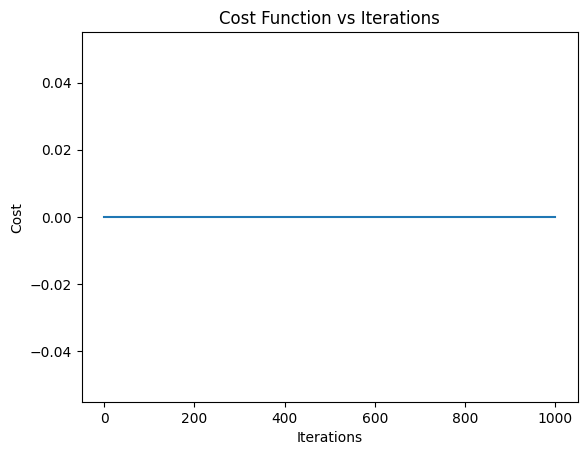

In [ ]:
#plot cost function
plt.plot(cost_history)
plt.xlabel("Iterations")
plt.ylabel("Cost")
plt.title("Cost Function vs Iterations")
plt.show()

In [ ]:
#make predictions
y_test_prob = hypothesis(X_test, w, b)

print("Predicted probabilities:")
print(y_test_prob[:10])

Predicted probabilities:
[nan nan nan nan nan nan nan nan nan nan]


In [ ]:
#convert probability to class
y_test_pred = (y_test_prob >= 0.5).astype(int)

print("Predicted classes:")
print(y_test_pred[:10])

Predicted classes:
[0 0 0 0 0 0 0 0 0 0]


In [ ]:
#accuracy
accuracy = np.mean(y_test_pred == y_test)

print("Accuracy:", accuracy)
print("Accuracy (%):", accuracy * 100)

Accuracy: 0.0
Accuracy (%): 0.0


Confusion Matrix:
[[ 8  0]
 [54  0]]
Accuracy:  0.12903225806451613
Precision: 0.0
Recall: 0.0
F1 Score: 0.0


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


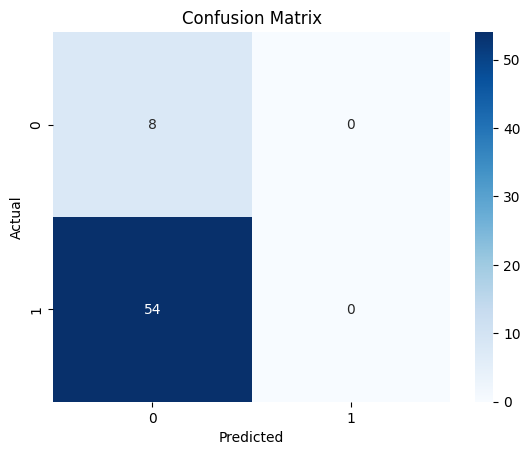

In [ ]:
#confusion matrix

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Convert y_test to numerical values (0 and 1) to match y_test_pred
y_test_numeric = y_test.map({'NO': 0, 'YES': 1})

cm = confusion_matrix(y_test_numeric, y_test_pred)

print("Confusion Matrix:")
print(cm)
accuracy = accuracy_score(y_test_numeric, y_test_pred)
print("Accuracy: ", accuracy)
precision = precision_score(y_test_numeric, y_test_pred)
print("Precision:", precision)
recall = recall_score(y_test_numeric, y_test_pred)
print("Recall:", recall)
f1 = f1_score(y_test_numeric, y_test_pred)
print("F1 Score:", f1)

import seaborn as sns

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [ ]:
#plot ROC Curve




SyntaxError: invalid character '→' (U+2192) (458783404.py, line 3)